<a href="https://colab.research.google.com/github/joem20/Planning-Europe/blob/main/Graph_Construction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Project Setup and Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# 2. Loading the Dataset

In [ ]:

# Load frozen Dataset v1 directly from GitHub
url = "https://raw.githubusercontent.com/joem20/Planning-Europe/dataset-v1/routes_dataset_v1.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (27, 14)


,link_id,from_city,to_city,mode,operator,service,duration_min,time_hours,price_original,currency_original,price_gbp,date_checked,source_url,notes
0,L01,London,Paris,rail,Eurostar,Eurostar,140,2.333,58.0,GBP,58.0,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,The fare is a promotional price. All fares car...
1,L02,London,Brussels,rail,Eurostar,Eurostar,124,2.067,120.0,GBP,120.0,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 09:01 London St Pancras to Brussels M...
2,L03,London,Amsterdam,rail,Eurostar,Eurostar,244,4.067,95.0,GBP,95.0,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 08:16 London St Pancras to Amsterdam ...
3,L04,Paris,Brussels,rail,Eurostar,Eurostar,84,1.400,38.5,GBP,38.5,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 08:53 Paris Nord to Brussels Midi 10:...
4,L05,Paris,Amsterdam,rail,Eurostar,Eurostar,209,3.483,35.5,GBP,35.5,2026-11-05,https://www.eurostar.com/search/uk-en?adult=1&...,Eurostar 12:21 Paris Nord to Amsterdam Centraa...


In [ ]:
print("NetworkX version:", nx.__version__)

NetworkX version: 3.7


## 2.1 Dataset Structure and Information

In [ ]:
# Dataset structure and information

print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of records: 27
Number of columns: 14

Column names:
['link_id', 'from_city', 'to_city', 'mode', 'operator', 'service', 'duration_min', 'time_hours', 'price_original', 'currency_original', 'price_gbp', 'date_checked', 'source_url', 'notes']

Data types:
link_id               object
from_city             object
to_city               object
mode                  object
operator              object
service               object
duration_min           int64
time_hours           float64
price_original       float64
currency_original     object
price_gbp            float64
date_checked          object
source_url            object
notes                 object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   link_id            27 non-null     object 
 1   from_city          27 non-null     object 
 2 

In [ ]:
# Data quality checks

print("MISSING VALUES")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

print("\nDUPLICATE RECORDS")
print("Exact duplicates:", df.duplicated().sum())

print("\nDUPLICATE LINK IDs")
print("Duplicate IDs:", df['link_id'].duplicated().sum())

MISSING VALUES
link_id              0
from_city            0
to_city              0
mode                 0
operator             0
service              0
duration_min         0
time_hours           0
price_original       0
currency_original    0
price_gbp            0
date_checked         0
source_url           0
notes                0
dtype: int64

TOTAL MISSING VALUES:
0

DUPLICATE RECORDS
Exact duplicates: 0

DUPLICATE LINK IDs
Duplicate IDs: 0


mode
rail     19
coach     8
Name: count, dtype: int64


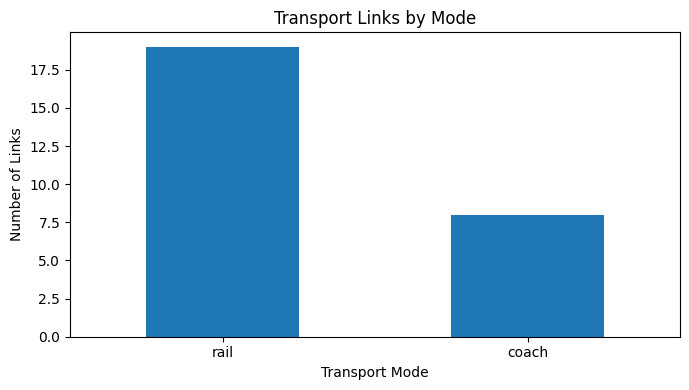

In [ ]:
# Transport mode distribution

mode_counts = df['mode'].value_counts()

print(mode_counts)

# Visualisation
mode_counts.plot(kind='bar', figsize=(7, 4))

plt.title('Transport Links by Mode')
plt.xlabel('Transport Mode')
plt.ylabel('Number of Links')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('transport_mode_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

operator
FlixBus               8
Eurostar              7
Deutsche Bahn         6
FlixTrain             2
SNCF Voyageurs/SBB    1
OUIGO                 1
SBB/Trenitalia        1
Trenitalia            1
Name: count, dtype: int64


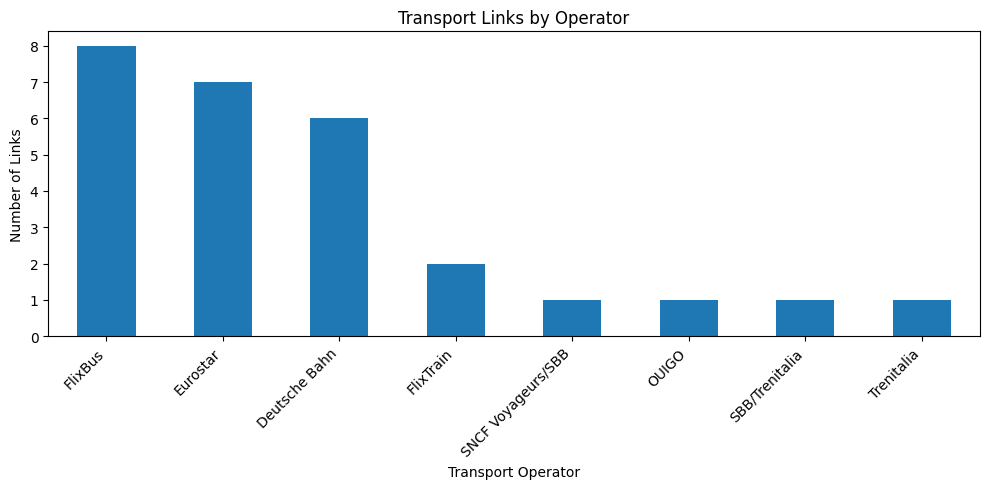

In [ ]:
# Operator distribution

operator_counts = df['operator'].value_counts()

print(operator_counts)

# Visualisation
operator_counts.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Transport Links by Operator')
plt.xlabel('Transport Operator')
plt.ylabel('Number of Links')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('operator_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Descriptive statistics

print("JOURNEY TIME STATISTICS")
print(df['duration_min'].describe())

print("\nGBP PRICE STATISTICS")
print(df['price_gbp'].describe())

print("\nAVERAGE PRICE BY MODE")
print(df.groupby('mode')['price_gbp'].mean())

print("\nAVERAGE JOURNEY TIME BY MODE")
print(df.groupby('mode')['duration_min'].mean())

JOURNEY TIME STATISTICS
count     27.00000
mean     267.37037
std      161.86275
min       69.00000
25%      132.00000
50%      240.00000
75%      372.50000
max      690.00000
Name: duration_min, dtype: float64

GBP PRICE STATISTICS
count     27.000000
mean      39.135185
std       27.039193
min        8.490000
25%       21.170000
50%       30.850000
75%       51.600000
max      120.000000
Name: price_gbp, dtype: float64

AVERAGE PRICE BY MODE
mode
coach    22.490000
rail     46.143684
Name: price_gbp, dtype: float64

AVERAGE JOURNEY TIME BY MODE
mode
coach    426.250000
rail     200.473684
Name: duration_min, dtype: float64


## 2.2 Routes with Multiple Transport Options

In [ ]:
# Identify routes with multiple transport options

analysis_df = df.copy()

# Treat routes as undirected
analysis_df['route'] = analysis_df.apply(
    lambda row: ' - '.join(
        sorted([row['from_city'], row['to_city']])
    ),
    axis=1
)

# Find routes with multiple links
route_counts = analysis_df['route'].value_counts()

multiple_routes = route_counts[route_counts > 1].index

alternatives = analysis_df[
    analysis_df['route'].isin(multiple_routes)
].sort_values(['route', 'price_gbp'])

# Display alternative services
display(
    alternatives[
        ['route', 'mode', 'operator',
         'duration_min', 'price_gbp']
    ]
)

,route,mode,operator,duration_min,price_gbp
19,Amsterdam - Berlin,coach,FlixBus,585,24.49
11,Amsterdam - Berlin,rail,Deutsche Bahn,410,65.04
18,Amsterdam - Brussels,coach,FlixBus,165,8.49
6,Amsterdam - Brussels,rail,Eurostar,117,56.50
16,Amsterdam - London,coach,FlixBus,690,48.99
2,Amsterdam - London,rail,Eurostar,244,95.00
20,Berlin - Cologne,rail,FlixTrain,384,9.99
25,Berlin - Cologne,rail,Deutsche Bahn,334,46.70
26,Berlin - Frankfurt,rail,FlixTrain,235,9.99
21,Berlin - Frankfurt,coach,FlixBus,485,22.49


In [ ]:
# Cheapest and fastest service per route

cheapest = alternatives.loc[
    alternatives.groupby('route')['price_gbp'].idxmin()
].copy()

fastest = alternatives.loc[
    alternatives.groupby('route')['duration_min'].idxmin()
].copy()

print("CHEAPEST SERVICE PER ROUTE")
display(cheapest[
    ['route', 'operator', 'mode',
     'duration_min', 'price_gbp']
])

print("\nFASTEST SERVICE PER ROUTE")
display(fastest[
    ['route', 'operator', 'mode',
     'duration_min', 'price_gbp']
])

CHEAPEST SERVICE PER ROUTE


,route,operator,mode,duration_min,price_gbp
19,Amsterdam - Berlin,FlixBus,coach,585,24.49
18,Amsterdam - Brussels,FlixBus,coach,165,8.49
16,Amsterdam - London,FlixBus,coach,690,48.99
20,Berlin - Cologne,FlixTrain,rail,384,9.99
26,Berlin - Frankfurt,FlixTrain,rail,235,9.99
8,Brussels - Cologne,Deutsche Bahn,rail,113,30.85
17,Brussels - Paris,FlixBus,coach,240,8.49
15,London - Paris,FlixBus,coach,500,28.49
23,Lyon - Milan,FlixBus,coach,365,21.49



FASTEST SERVICE PER ROUTE


,route,operator,mode,duration_min,price_gbp
11,Amsterdam - Berlin,Deutsche Bahn,rail,410,65.04
6,Amsterdam - Brussels,Eurostar,rail,117,56.50
2,Amsterdam - London,Eurostar,rail,244,95.00
25,Berlin - Cologne,Deutsche Bahn,rail,334,46.70
26,Berlin - Frankfurt,FlixTrain,rail,235,9.99
7,Brussels - Cologne,Eurostar,rail,110,48.00
3,Brussels - Paris,Eurostar,rail,84,38.50
0,London - Paris,Eurostar,rail,140,58.00
24,Lyon - Milan,Trenitalia,rail,284,54.21


## 2.3 Generalised Cost Analysis

In [ ]:
# Generalised cost analysis

# Create a separate analysis copy.
# Dataset v1 remains unchanged.

cost_analysis = df.copy()

# Calculate generalised cost under three scenarios

lambda_values = [5, 10, 20]

for lam in lambda_values:
    column_name = f'cost_lambda_{lam}'

    cost_analysis[column_name] = (
        cost_analysis['price_gbp']
        + lam * cost_analysis['time_hours']
    )

# Display all 27 links with their calculated costs

display(
    cost_analysis[
        ['from_city', 'to_city', 'operator',
         'mode', 'price_gbp', 'time_hours',
         'cost_lambda_5',
         'cost_lambda_10',
         'cost_lambda_20']
    ].round(2)
)

,from_city,to_city,operator,mode,price_gbp,time_hours,cost_lambda_5,cost_lambda_10,cost_lambda_20
0,London,Paris,Eurostar,rail,58.00,2.33,69.67,81.33,104.66
1,London,Brussels,Eurostar,rail,120.00,2.07,130.34,140.67,161.34
2,London,Amsterdam,Eurostar,rail,95.00,4.07,115.34,135.67,176.34
3,Paris,Brussels,Eurostar,rail,38.50,1.40,45.50,52.50,66.50
4,Paris,Amsterdam,Eurostar,rail,35.50,3.48,52.92,70.33,105.16
5,Paris,Lyon,OUIGO,rail,20.85,1.93,30.52,40.18,59.51
6,Brussels,Amsterdam,Eurostar,rail,56.50,1.95,66.25,76.00,95.50
7,Brussels,Cologne,Eurostar,rail,48.00,1.83,57.16,66.33,84.66
8,Brussels,Cologne,Deutsche Bahn,rail,30.85,1.88,40.26,49.68,68.51
9,Amsterdam,Cologne,Deutsche Bahn,rail,21.68,2.55,34.43,47.18,72.68


### 2.4 Lowest Generalised-Cost Service by Route

In [ ]:
# Find the lowest generalised-cost service per route

# Create undirected route identifiers
cost_analysis['route'] = cost_analysis.apply(
    lambda row: ' - '.join(
        sorted([row['from_city'], row['to_city']])
    ),
    axis=1
)

# Only examine routes with multiple transport options
multiple_routes = (
    cost_analysis['route'].value_counts()
)
multiple_routes = multiple_routes[
    multiple_routes > 1
].index

route_results = cost_analysis[
    cost_analysis['route'].isin(multiple_routes)
].copy()

# Compare winning services under each lambda
for lam in [5, 10, 20]:

    column = f'cost_lambda_{lam}'

    winners = route_results.loc[
        route_results.groupby('route')[column].idxmin()
    ]

    print(f"\nWINNING SERVICES - LAMBDA = £{lam}/hour")

    display(
        winners[
            ['route', 'operator', 'mode', column]
        ].sort_values('route').round(2)
    )


WINNING SERVICES - LAMBDA = £5/hour


,route,operator,mode,cost_lambda_5
19,Amsterdam - Berlin,FlixBus,coach,73.24
18,Amsterdam - Brussels,FlixBus,coach,22.24
16,Amsterdam - London,FlixBus,coach,106.49
20,Berlin - Cologne,FlixTrain,rail,41.99
26,Berlin - Frankfurt,FlixTrain,rail,29.58
8,Brussels - Cologne,Deutsche Bahn,rail,40.26
17,Brussels - Paris,FlixBus,coach,28.49
0,London - Paris,Eurostar,rail,69.67
23,Lyon - Milan,FlixBus,coach,51.90



WINNING SERVICES - LAMBDA = £10/hour


,route,operator,mode,cost_lambda_10
19,Amsterdam - Berlin,FlixBus,coach,121.99
18,Amsterdam - Brussels,FlixBus,coach,35.99
2,Amsterdam - London,Eurostar,rail,135.67
20,Berlin - Cologne,FlixTrain,rail,73.99
26,Berlin - Frankfurt,FlixTrain,rail,49.16
8,Brussels - Cologne,Deutsche Bahn,rail,49.68
17,Brussels - Paris,FlixBus,coach,48.49
0,London - Paris,Eurostar,rail,81.33
23,Lyon - Milan,FlixBus,coach,82.32



WINNING SERVICES - LAMBDA = £20/hour


,route,operator,mode,cost_lambda_20
11,Amsterdam - Berlin,Deutsche Bahn,rail,201.70
18,Amsterdam - Brussels,FlixBus,coach,63.49
2,Amsterdam - London,Eurostar,rail,176.34
20,Berlin - Cologne,FlixTrain,rail,137.99
26,Berlin - Frankfurt,FlixTrain,rail,88.33
8,Brussels - Cologne,Deutsche Bahn,rail,68.51
3,Brussels - Paris,Eurostar,rail,66.50
0,London - Paris,Eurostar,rail,104.66
23,Lyon - Milan,FlixBus,coach,143.15


In [ ]:
# Count changes in winning services

winning_results = {}

for lam in [5, 10, 20]:

    column = f'cost_lambda_{lam}'

    winners = route_results.loc[
        route_results.groupby('route')[column].idxmin()
    ]

    winning_results[lam] = (
        winners.set_index('route')['operator']
    )

comparison = pd.DataFrame(winning_results)

print("WINNING OPERATOR COMPARISON")
display(comparison)

print("\nCHANGES BETWEEN SCENARIOS")

print(
    "£5 to £10:",
    (comparison[5] != comparison[10]).sum()
)

print(
    "£10 to £20:",
    (comparison[10] != comparison[20]).sum()
)

print(
    "£5 to £20:",
    (comparison[5] != comparison[20]).sum()
)

WINNING OPERATOR COMPARISON


,5,10,20
route,,,
Amsterdam - Berlin,FlixBus,FlixBus,Deutsche Bahn
Amsterdam - Brussels,FlixBus,FlixBus,FlixBus
Amsterdam - London,FlixBus,Eurostar,Eurostar
Berlin - Cologne,FlixTrain,FlixTrain,FlixTrain
Berlin - Frankfurt,FlixTrain,FlixTrain,FlixTrain
Brussels - Cologne,Deutsche Bahn,Deutsche Bahn,Deutsche Bahn
Brussels - Paris,FlixBus,FlixBus,Eurostar
London - Paris,Eurostar,Eurostar,Eurostar
Lyon - Milan,FlixBus,FlixBus,FlixBus



CHANGES BETWEEN SCENARIOS
£5 to £10: 1
£10 to £20: 2
£5 to £20: 3


# 3. Graph Construction

In [ ]:

# Creating Graph
G = nx.MultiGraph()

# Getting unique cities from both columns
cities = set(df['from_city']).union(set(df['to_city']))

# Adding nodes to the graph
G.add_nodes_from(cities)
# Print results
print(f"Number of nodes in the graph: {G.number_of_nodes()}")

print("\nCities:")
for city in sorted(G.nodes()):
    print(city)

Number of nodes in the graph: 10

Cities:
Amsterdam
Berlin
Brussels
Cologne
Frankfurt
London
Lyon
Milan
Paris
Zurich


In [ ]:
print(df.columns.tolist())

['link_id', 'from_city', 'to_city', 'mode', 'operator', 'service', 'duration_min', 'time_hours', 'price_original', 'currency_original', 'price_gbp', 'date_checked', 'source_url', 'notes']


In [ ]:
# Add transport connections (edges)

for _, row in df.iterrows():

    G.add_edge(
        row["from_city"],
        row["to_city"],
        key=row["link_id"],

        mode=row["mode"],
        operator=row["operator"],
        price_gbp=row["price_gbp"],
        time_hours=row["time_hours"],
        duration_min=row["duration_min"]
    )

# Check graph size
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 10
Number of edges: 27


In [ ]:
# Check whether the graph is connected

if nx.is_connected(G):
    print("The graph is connected.")
else:
    print("The graph is not connected.")

The graph is connected.


In [ ]:
for city, degree in sorted(G.degree(), key=lambda x: x[1], reverse=True):
    print(city, degree)

Amsterdam 8
Brussels 7
Berlin 7
Paris 7
Cologne 6
Frankfurt 5
London 5
Lyon 3
Zurich 3
Milan 3


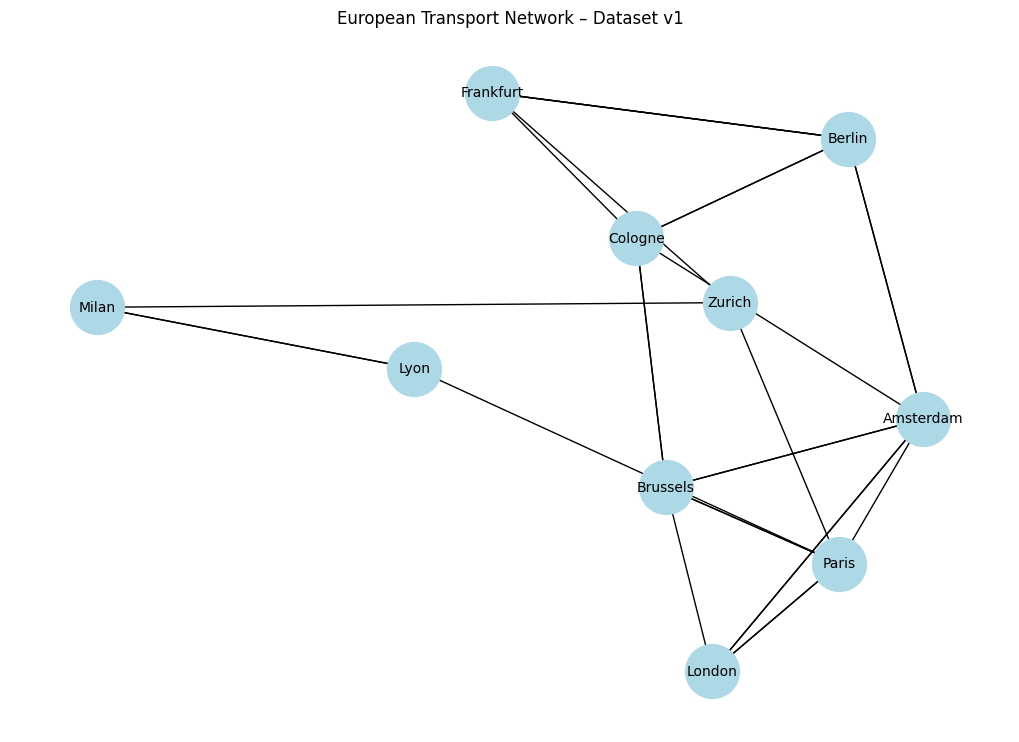

In [ ]:
# Graph visualisation

# Create a layout for the graph
pos = nx.spring_layout(G, seed=7, k=1.5)

# Set figure size
plt.figure(figsize=(10, 7))

# Draw the network
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1500,
    node_color="lightblue",
    font_size=10
)

# Add title
plt.title("European Transport Network – Dataset v1")

# Save high-resolution image
plt.savefig(
    "european_transport_network.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
def set_generalised_costs(G, lam):

    # Check that lambda is valid
    if lam < 0:
        raise ValueError("lambda must be non-negative")

    for _, _, _, data in G.edges(keys=True, data=True):

        price = data["price_gbp"]
        time = data["time_hours"]

        data["generalised_cost"] = price + lam * time

    return G

In [ ]:
# Calculate generalised costs using lambda = £10/hour
set_generalised_costs(G, 10)

print("Generalised costs calculated successfully.")

Generalised costs calculated successfully.


In [ ]:
print(G["London"]["Paris"]["L01"]["generalised_cost"])

81.33


In [ ]:
def dijkstra(G, start, destination):

    # initialises distance
    distances = {}
    for city in G.nodes():
        distances[city] = float("inf")

    distances[start] = 0
    # cities still to be processed
    unvisited = set(G.nodes())
    # store the previous city on the shortest path
    previous = {}

    while unvisited:

        current_city = None
        smallest_distance = float("inf")

        for city in unvisited:
            if distances[city] < smallest_distance:
                smallest_distance = distances[city]
                current_city = city

        # stop if no reachable city remains
        if current_city is None:
            break

        # stop if destination has been reached
        if current_city == destination:
            break

        # mark current city as visited
        unvisited.remove(current_city)

        # examine neigbouring cities
        for neighbour in G.neighbors(current_city):

            # only consider cities not visited
            if neighbour in unvisited:

                # examine each transport link between the cities
                for link_id, data in G[current_city][neighbour].items():

                    new_distance = distances[current_city] + data["generalised_cost"]

                    if new_distance < distances[neighbour]:
                        distances[neighbour] = new_distance
                        previous[neighbour] = (current_city, link_id)

    return distances, previous


In [ ]:
distances, previous = dijkstra(G, "London", "Paris")

print("Shortest generalised cost:", distances["Paris"])
print("Previous link:", previous["Paris"])

Shortest generalised cost: 81.33
Previous link: ('London', 'L01')


In [ ]:
# T09 - Create a small MultiGraph for testing

T = nx.MultiGraph()

# Add connections with generalised costs
T.add_edge("A", "B", key="AB", generalised_cost=4)
T.add_edge("A", "C", key="AC", generalised_cost=2)
T.add_edge("C", "B", key="CB", generalised_cost=1)
T.add_edge("B", "D", key="BD", generalised_cost=5)
T.add_edge("C", "D", key="CD", generalised_cost=8)

print("Test graph created.")
print("Nodes:", list(T.nodes()))
print("Edges:", list(T.edges(keys=True, data=True)))

Test graph created.
Nodes: ['A', 'B', 'C', 'D']
Edges: [('A', 'B', 'AB', {'generalised_cost': 4}), ('A', 'C', 'AC', {'generalised_cost': 2}), ('B', 'C', 'CB', {'generalised_cost': 1}), ('B', 'D', 'BD', {'generalised_cost': 5}), ('C', 'D', 'CD', {'generalised_cost': 8})]


In [ ]:
# Running Dijkstra algorithm on the test graph

test_distances, test_previous = dijkstra(T, "A", "D")

print("Shortest cost:", test_distances["D"])
print("Previous node and link:", test_previous["D"])

Shortest cost: 8
Previous node and link: ('B', 'BD')


In [ ]:
# Reconstruct the route from D back to A

route = ["D"]
current = "D"

while current != "A":
    current = test_previous[current][0]
    route.append(current)

route.reverse()

print("Shortest route:", " -> ".join(route))

Shortest route: A -> C -> B -> D


In [ ]:
# T04 - London to Paris with lambda = 0

# Calculate costs using price only
set_generalised_costs(G, 0)

# Run Dijkstra
t04_distances, t04_previous = dijkstra(G, "London", "Paris")

# Display results
print("Lambda:", 0)
print("Shortest generalised cost:", t04_distances["Paris"])
print("Previous city and link:", t04_previous["Paris"])

# Reset graph costs to lambda = 10 for subsequent tests
set_generalised_costs(G, 10)

Lambda: 0
Shortest generalised cost: 28.49
Previous city and link: ('London', 'L16')


In [ ]:
# T05 - Create a graph with an unreachable destination

T5 = nx.MultiGraph()

# Add the connected section
T5.add_edge("A", "B", key="AB", generalised_cost=4)
T5.add_edge("B", "C", key="BC", generalised_cost=3)

# Add D as an isolated node
T5.add_node("D")

print("Nodes:", list(T5.nodes()))
print("Edges:", list(T5.edges(keys=True, data=True)))

Nodes: ['A', 'B', 'C', 'D']
Edges: [('A', 'B', 'AB', {'generalised_cost': 4}), ('B', 'C', 'BC', {'generalised_cost': 3})]


In [ ]:
# Run Dijkstra from A to D

t05_distances, t05_previous = dijkstra(T5, "A", "D")

print("Shortest cost:", t05_distances["D"])
print("Is destination unreachable:", t05_distances["D"] == float("inf"))

Shortest cost: inf
Is destination unreachable: True


In [ ]:
# T08 - Test negative lambda validation

try:
    set_generalised_costs(G, -1)
    print("FAIL: Negative lambda was accepted.")

except ValueError as error:
    print("PASS: Negative lambda rejected.")
    print("Error:", error)
    set_generalised_costs(G, 10)

PASS: Negative lambda rejected.
Error: lambda must be non-negative


In [ ]:
# T02 - Multi-connection journey: Lyon to Zurich

# Set generalised costs to lambda = £10 per hour
set_generalised_costs(G, 10)

# Run Dijkstra
t02_distances, t02_previous = dijkstra(G, "Lyon", "Zurich")

# Reconstruct the route
current = "Zurich"
route_cities = ["Zurich"]
route_links = []

while current != "Lyon":
    previous_city, link_id = t02_previous[current]
    route_links.append(link_id)
    current = previous_city
    route_cities.append(current)

route_cities.reverse()
route_links.reverse()

# Display results
print("Lambda: £10 per hour")
print("Route:", " -> ".join(route_cities))
print("Transport links:", route_links)
print("Shortest generalised cost: £", round(t02_distances["Zurich"], 2))

Lambda: £10 per hour
Route: Lyon -> Milan -> Zurich
Transport links: ['L24', 'L15']
Shortest generalised cost: £ 144.32


In [ ]:
# T03 - Compare own Dijkstra with NetworkX

# Set generalised costs using lambda = £10/hour
set_generalised_costs(G, 10)

In [ ]:
# Run  Dijkstra algorithm
own_distances, own_previous = dijkstra(G, "Lyon", "Zurich")

print("Our Dijkstra result:", round(own_distances["Zurich"], 2))

Our Dijkstra result: 144.32


In [ ]:
# Calculate shortest path using NetworkX
nx_cost = nx.shortest_path_length(
    G,
    source="Lyon",
    target="Zurich",
    weight="generalised_cost"
)

print("NetworkX result:", round(nx_cost, 2))

NetworkX result: 144.32


In [ ]:
# Compare both results
if abs(own_distances["Zurich"] - nx_cost) < 0.000001:
    print("PASS: Both algorithms return the same minimum cost.")
else:
    print("FAIL: The results do not match.")

PASS: Both algorithms return the same minimum cost.


In [ ]:

# T03 - Full comparison of own Dijkstra with NetworkX

lambda_values = [0, 5, 10, 20, 30]

matches = 0
mismatches = []

total_comparisons = 0

# Test every lambda value
for lam in lambda_values:

    set_generalised_costs(G, lam)

    # Test every ordered pair of different cities
    for source in G.nodes():

        for target in G.nodes():

            if source != target:

                total_comparisons += 1

                # Run our own Dijkstra
                own_distances, own_previous = dijkstra(G, source, target)
                own_cost = own_distances[target]

                # Run NetworkX
                try:
                    nx_cost = nx.shortest_path_length(
                        G,
                        source=source,
                        target=target,
                        weight="generalised_cost"
                    )

                except nx.NetworkXNoPath:
                    nx_cost = float("inf")

                # Compare results
                if abs(own_cost - nx_cost) < 1e-9:
                    matches += 1

                else:
                    mismatches.append(
                        (lam, source, target, own_cost, nx_cost)
                    )

# Reset graph to lambda = 10
set_generalised_costs(G, 10)

# Display summary
print("T03 - Full Dijkstra comparison")
print("------------------------------")
print("Total comparisons:", total_comparisons)
print("Matches:", matches)
print("Mismatches:", len(mismatches))
print("Lambda values:", lambda_values)

print("\nMismatch details:")
for mismatch in mismatches:
    print(mismatch)


T03 - Full Dijkstra comparison
------------------------------
Total comparisons: 450
Matches: 450
Mismatches: 0
Lambda values: [0, 5, 10, 20, 30]

Mismatch details:


In [ ]:
print("Number of cities:", G.number_of_nodes())
print("Number of transport links:", G.number_of_edges())
print("Graph connected:", nx.is_connected(G))

Number of cities: 10
Number of transport links: 27
Graph connected: True


In [ ]:

# T06 - Lambda sensitivity: Lyon to Zurich

lambda_values = [0, 5, 10, 20, 30]

for lam in lambda_values:

    # Calculate generalised costs
    set_generalised_costs(G, lam)

    # Run Dijkstra
    distances, previous = dijkstra(G, "Lyon", "Zurich")

    # Reconstruct the route
    current = "Zurich"
    route_cities = ["Zurich"]
    route_links = []

    while current != "Lyon":
        previous_city, link_id = previous[current]
        route_links.append(link_id)
        current = previous_city
        route_cities.append(current)

    route_cities.reverse()
    route_links.reverse()

    # Display results
    print(f"\nLambda: £{lam}/hour")
    print("Route:", " -> ".join(route_cities))
    print("Links:", route_links)
    print("Generalised cost: £", round(distances["Zurich"], 2))

# Restore lambda to £10/hour
set_generalised_costs(G, 10)



Lambda: £0/hour
Route: Lyon -> Milan -> Zurich
Links: ['L24', 'L15']
Generalised cost: £ 50.66

Lambda: £5/hour
Route: Lyon -> Milan -> Zurich
Links: ['L24', 'L15']
Generalised cost: £ 97.49

Lambda: £10/hour
Route: Lyon -> Milan -> Zurich
Links: ['L24', 'L15']
Generalised cost: £ 144.32

Lambda: £20/hour
Route: Lyon -> Paris -> Zurich
Links: ['L06', 'L14']
Generalised cost: £ 216.74

Lambda: £30/hour
Route: Lyon -> Paris -> Zurich
Links: ['L06', 'L14']
Generalised cost: £ 276.74


In [ ]:

# T06 - Full network lambda sensitivity analysis

lambda_values = [0, 5, 10, 20, 30]

sensitivity_results = []

for lam in lambda_values:

    set_generalised_costs(G, lam)

    for source in sorted(G.nodes()):

        for target in sorted(G.nodes()):

            if source != target:

                distances, previous = dijkstra(G, source, target)

                # Reconstruct the winning route
                current = target
                route_links = []

                while current != source:
                    previous_city, link_id = previous[current]
                    route_links.append(link_id)
                    current = previous_city

                route_links.reverse()

                # Store the result
                sensitivity_results.append({
                    "lambda": lam,
                    "source": source,
                    "target": target,
                    "links": tuple(route_links),
                    "cost": round(distances[target], 2)
                })

# Restore lambda to 10
set_generalised_costs(G, 10)

print("Total route calculations:", len(sensitivity_results))
print("First five results:")

for result in sensitivity_results[:5]:
    print(result)


Total route calculations: 450
First five results:
{'lambda': 0, 'source': 'Amsterdam', 'target': 'Berlin', 'links': ('L20',), 'cost': 24.49}
{'lambda': 0, 'source': 'Amsterdam', 'target': 'Brussels', 'links': ('L19',), 'cost': 8.49}
{'lambda': 0, 'source': 'Amsterdam', 'target': 'Cologne', 'links': ('L10',), 'cost': 21.68}
{'lambda': 0, 'source': 'Amsterdam', 'target': 'Frankfurt', 'links': ('L20', 'L27'), 'cost': 34.48}
{'lambda': 0, 'source': 'Amsterdam', 'target': 'London', 'links': ('L19', 'L18', 'L16'), 'cost': 45.47}


In [ ]:
# T06b - Compare routes across lambda values

route_changes = []

for source in sorted(G.nodes()):

    for target in sorted(G.nodes()):

        if source != target:

            # Get results for this city pair at each lambda
            pair_results = [
                result for result in sensitivity_results
                if result["source"] == source
                and result["target"] == target
            ]

            # Sort results by lambda
            pair_results.sort(key=lambda x: x["lambda"])

            # Check whether the selected links change
            routes = [result["links"] for result in pair_results]

            if len(set(routes)) > 1:
                route_changes.append({
                    "source": source,
                    "target": target,
                    "routes": routes,
                    "lambdas": [result["lambda"] for result in pair_results]
                })

print("City pairs with route changes:", len(route_changes))
print("\nRoute change details:")

for change in route_changes:
    print(change)

City pairs with route changes: 66

Route change details:
{'source': 'Amsterdam', 'target': 'Berlin', 'routes': [('L20',), ('L20',), ('L10', 'L21'), ('L12',), ('L12',)], 'lambdas': [0, 5, 10, 20, 30]}
{'source': 'Amsterdam', 'target': 'Frankfurt', 'routes': [('L20', 'L27'), ('L10', 'L11'), ('L10', 'L11'), ('L10', 'L11'), ('L10', 'L11')], 'lambdas': [0, 5, 10, 20, 30]}
{'source': 'Amsterdam', 'target': 'London', 'routes': [('L19', 'L18', 'L16'), ('L17',), ('L03',), ('L03',), ('L03',)], 'lambdas': [0, 5, 10, 20, 30]}
{'source': 'Amsterdam', 'target': 'Lyon', 'routes': [('L19', 'L18', 'L06'), ('L19', 'L18', 'L06'), ('L05', 'L06'), ('L05', 'L06'), ('L05', 'L06')], 'lambdas': [0, 5, 10, 20, 30]}
{'source': 'Amsterdam', 'target': 'Milan', 'routes': [('L19', 'L18', 'L06', 'L24'), ('L19', 'L18', 'L06', 'L24'), ('L05', 'L06', 'L24'), ('L05', 'L06', 'L24'), ('L05', 'L06', 'L25')], 'lambdas': [0, 5, 10, 20, 30]}
{'source': 'Amsterdam', 'target': 'Paris', 'routes': [('L19', 'L18'), ('L19', 'L18'), 

In [ ]:

# T06b - Count route changes between lambda values

transition_counts = {
    "0 to 5": 0,
    "5 to 10": 0,
    "10 to 20": 0,
    "20 to 30": 0
}

for change in route_changes:

    routes = change["routes"]

    if routes[0] != routes[1]:
        transition_counts["0 to 5"] += 1

    if routes[1] != routes[2]:
        transition_counts["5 to 10"] += 1

    if routes[2] != routes[3]:
        transition_counts["10 to 20"] += 1

    if routes[3] != routes[4]:
        transition_counts["20 to 30"] += 1

print("Route changes between lambda values:")

for interval, count in transition_counts.items():
    print(interval, ":", count)

# Count unique unordered city pairs
unique_changed_pairs = {
    tuple(sorted((change["source"], change["target"])))
    for change in route_changes
}

print("\nUnique city pairs with route changes:", len(unique_changed_pairs))


Route changes between lambda values:
0 to 5 : 44
5 to 10 : 12
10 to 20 : 36
20 to 30 : 12

Unique city pairs with route changes: 33


In [ ]:

from collections import Counter

# T06b - Count selected transport links at each lambda value

for lam in lambda_values:

    # Select results for this lambda
    lambda_results = [
        result for result in sensitivity_results
        if result["lambda"] == lam
    ]

    # Count how often each link is selected
    link_counts = Counter()

    for result in lambda_results:
        link_counts.update(result["links"])

    print(f"\nMost frequently selected links at lambda = £{lam}/hour")
    print("-" * 55)

    for link_id, count in link_counts.most_common(10):
        # Retrieve link information from the dataset
        link = df[df["link_id"] == link_id].iloc[0]

        print(
            link_id,
            "|", link["from_city"], "->", link["to_city"],
            "|", link["mode"],
            "| Selected:", count
        )



Most frequently selected links at lambda = £0/hour
-------------------------------------------------------
L19 | Brussels -> Amsterdam | coach | Selected: 38
L18 | Paris -> Brussels | coach | Selected: 36
L20 | Amsterdam -> Berlin | coach | Selected: 26
L27 | Frankfurt -> Berlin | rail | Selected: 22
L23 | Frankfurt -> Zurich | coach | Selected: 22
L06 | Paris -> Lyon | rail | Selected: 20
L16 | London -> Paris | coach | Selected: 18
L24 | Lyon -> Milan | coach | Selected: 14
L15 | Zurich -> Milan | rail | Selected: 12
L10 | Amsterdam -> Cologne | rail | Selected: 10

Most frequently selected links at lambda = £5/hour
-------------------------------------------------------
L18 | Paris -> Brussels | coach | Selected: 30
L09 | Brussels -> Cologne | rail | Selected: 24
L06 | Paris -> Lyon | rail | Selected: 22
L11 | Cologne -> Frankfurt | rail | Selected: 20
L23 | Frankfurt -> Zurich | coach | Selected: 16
L01 | London -> Paris | rail | Selected: 14
L24 | Lyon -> Milan | coach | Selected

In [ ]:
from collections import Counter

for lam in [20, 30]:
    link_counts = Counter()

    for result in sensitivity_results:
        if result["lambda"] == lam:
            link_counts.update(result["links"])

    print(f"\nTop 12 links at lambda = £{lam}/hour")

    for link_id, count in link_counts.most_common(12):
        print(link_id, count)


Top 12 links at lambda = £20/hour
L11 28
L06 24
L09 24
L04 20
L27 16
L23 14
L24 10
L02 8
L15 8
L14 8
L01 8
L10 6

Top 12 links at lambda = £30/hour
L11 26
L06 24
L09 24
L04 20
L27 16
L23 12
L25 10
L14 10
L05 8
L02 8
L15 8
L01 8
